# 03 · USDA NASS cattle inventory and cow slaughter

**Milestone 1, items 1.4 and 1.5** · see `docs/MILESTONES.md`

## What we're looking for

This notebook gets the data to test the cause chain in decision D17:

**drought → less grazing → ranchers sell off cows → smaller herd → fewer cattle →
higher beef prices**

Two kinds of data from USDA's National Agricultural Statistics Service (NASS):

| Data | What it shows | Link in the chain |
|---|---|---|
| **Cattle inventory** | How many cattle and beef cows are on U.S. farms and ranches, counted each January 1 (and mid-year) | "smaller herd" |
| **Cow slaughter** | How many cows are slaughtered each month | "ranchers sell off cows": a sell-off shows up here first, as a spike |

**Why cows specifically?** Steers and heifers raised for beef are slaughtered every year
as normal business. **Cows** are the breeding herd: every cow slaughtered is one fewer
calf next year and the year after. A jump in cow slaughter means ranchers are shrinking
their herds, which is exactly what happens in a drought.

**Why start in 2010, not 2015?** The cattle cycle is slow, so we need the years before
2015 for context. Ranchers sold off cows in the 2011–2013 drought (mainly Texas and the
southern Plains), rebuilt the herd from about 2014 to 2019, then sold off again. Seeing
the earlier cycle helps us judge whether the recent one is unusual (decision D24).

**Like notebook 02, this has two parts.** Part 1 downloads and takes an inventory: NASS
has many similar-sounding series, so we'll choose which ones to use together before
Part 2 builds the tables.

**Steps (Part 1)**
1. Setup and API key
2. The two queries
3. Check the record counts (NASS limits each request to 50,000 rows)
4. Download and save the raw responses
5. Load into tables
6. Inventory: every series, its time period and its coverage

## Step 1 · Setup and API key

Same approach as notebook 01: the key is read from `.env` and never printed.

In [8]:
import json
import os
from datetime import date
from pathlib import Path

import pandas as pd
import requests
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv()
load_dotenv(env_path)
NASS_API_KEY = os.getenv("NASS_API_KEY", "").strip()

PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / f"nass_{date.today():%Y%m%d}"
RAW_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 90)

print("Project root:", PROJECT_ROOT)
print("API key found:", bool(NASS_API_KEY), "| length:", len(NASS_API_KEY))

Project root: B:\_Dev\Python\meat-prices
API key found: True | length: 36


### How to read it
**API key found** should be `True`. If it's `False`, check the `.env` line reads exactly
`NASS_API_KEY=yourkey`, then restart the kernel.

## Step 2 · The two queries

NASS's Quick Stats API is searched with filters. Each filter narrows the results:

| Filter | Value | Meaning |
|---|---|---|
| `commodity_desc` | CATTLE | Cattle data only |
| `statisticcat_desc` | INVENTORY / SLAUGHTERED | Head counts on farms, or animals slaughtered |
| `agg_level_desc` | NATIONAL | U.S. totals, not state or county |
| `source_desc` | SURVEY | NASS's regular surveys (not the 5-yearly Census of Agriculture) |
| `year__GE` | 2010 | Years greater than or equal to 2010 |
| `freq_desc` | MONTHLY | Slaughter only: monthly figures |

We don't narrow further (for example to "beef cows" only) yet, because we want to see
every series NASS has before choosing.

In [9]:
NASS_BASE = "https://quickstats.nass.usda.gov/api"

QUERIES = {
    "inventory": {
        "commodity_desc": "CATTLE",
        "statisticcat_desc": "INVENTORY",
        "agg_level_desc": "NATIONAL",
        "source_desc": "SURVEY",
        "year__GE": "2010",
    },
    "slaughter": {
        "commodity_desc": "CATTLE",
        "statisticcat_desc": "SLAUGHTERED",
        "agg_level_desc": "NATIONAL",
        "source_desc": "SURVEY",
        "freq_desc": "MONTHLY",
        "year__GE": "2010",
    },
}

pd.DataFrame(QUERIES).fillna("")

,inventory,slaughter
commodity_desc,CATTLE,CATTLE
statisticcat_desc,INVENTORY,SLAUGHTERED
agg_level_desc,NATIONAL,NATIONAL
source_desc,SURVEY,SURVEY
year__GE,2010,2010
freq_desc,,MONTHLY


## Step 3 · Check the record counts

NASS refuses any request that would return more than 50,000 rows, so we ask how many
rows each query would return before downloading. `get_counts` is a separate NASS
endpoint that returns only the count.

In [10]:
def nass_get(endpoint, params):
    """Call a NASS Quick Stats endpoint and return the parsed JSON."""
    full = {"key": NASS_API_KEY, "format": "JSON", **params}
    resp = requests.get(f"{NASS_BASE}/{endpoint}/", params=full, timeout=120)
    if resp.status_code != 200:
        # NASS explains errors in the body; don't print resp.url, it contains the key
        raise RuntimeError(f"NASS {endpoint} failed ({resp.status_code}): {resp.text[:300]}")
    return resp.json()

for name, params in QUERIES.items():
    count = int(nass_get("get_counts", params)["count"])
    flag = "OK" if count <= 50_000 else "TOO MANY - narrow the query"
    print(f"{name:10} {count:>8,} rows  {flag}")

inventory     1,076 rows  OK
slaughter     5,226 rows  OK


### How to read it
One line per query with the number of rows it would return. Both should say **OK**.
If one says TOO MANY, tell me and we'll split it (for example by year).

## Step 4 · Download and save

Same rule as before: save exactly what NASS sends, untouched, in a dated folder.

In [11]:
raw = {}
for name, params in QUERIES.items():
    data = nass_get("api_GET", params)
    raw[name] = data["data"]
    path = RAW_DIR / f"{name}.json"
    path.write_text(json.dumps(data, indent=1))
    print(f"{name:10} {len(raw[name]):>8,} rows  ->  {path.relative_to(PROJECT_ROOT)}")

inventory     1,076 rows  ->  data\raw\nass_20261026\inventory.json
slaughter     5,226 rows  ->  data\raw\nass_20261026\slaughter.json


## Step 5 · Load into tables

Each NASS row has about 40 fields. We keep the ones that identify the series and its
time period:

| Field | Meaning |
|---|---|
| `short_desc` | The series name, e.g. *CATTLE, COWS, BEEF - INVENTORY* |
| `year` | Year |
| `reference_period_desc` | The period within the year: *FIRST OF JAN*, *FIRST OF JUL*, or a month (*JAN*, *FEB*…) |
| `freq_desc` | ANNUAL, POINT IN TIME, MONTHLY… |
| `Value` | The number, as text |
| `unit_desc` | Units, e.g. HEAD |

**About `Value`:** NASS writes numbers with thousands commas (`28,700,000`, the same
problem as ERS) and uses codes for values it can't publish: `(D)` = withheld to protect
individual operations, `(NA)` = not available, `(Z)` = less than half the unit shown. We
strip the commas and turn the codes into missing values, keeping the original text in
`value_raw` so nothing is lost.

In [12]:
KEEP = ["short_desc", "year", "reference_period_desc", "freq_desc",
        "begin_code", "end_code", "Value", "unit_desc", "class_desc", "domain_desc"]

def to_frame(rows, query_name):
    df = pd.DataFrame(rows)
    df = df[[col for col in KEEP if col in df.columns]].copy()
    df["value_raw"] = df["Value"].astype(str).str.strip()
    df["value"] = pd.to_numeric(df["value_raw"].str.replace(",", "", regex=False), errors="coerce")
    df["year"] = df["year"].astype(int)
    df["query"] = query_name
    return df.drop(columns="Value")

tables = {name: to_frame(rows, name) for name, rows in raw.items()}

for name, df in tables.items():
    codes = df.loc[df["value"].isna(), "value_raw"].value_counts().to_dict()
    print(f"{name:10} {len(df):>7,} rows | {df['short_desc'].nunique():>3} series | "
          f"{df['year'].min()}-{df['year'].max()} | not numeric: {codes or 'none'}")

inventory    1,076 rows |  25 series | 2010-2026 | not numeric: none
slaughter    5,226 rows |  26 series | 2010-2026 | not numeric: none


### How to read it
For each query: rows, number of distinct series, the year range, and any values that
weren't numbers (with their codes and how many times each appears).

## Step 6 · Inventory of series

**What we're looking for:** the exact names of the series we need:
- **Inventory:** total cattle and **beef cows** on January 1 (and July 1, if published),
  every year from 2010.
- **Slaughter:** monthly **cow** slaughter, ideally split into beef cows and dairy cows,
  since only beef cows matter for the beef herd.

One series can have several time periods (January 1 and July 1, or annual totals and
months), so we list each series with each period it comes in.

In [13]:
def inventory_of(df):
    return (
        df.groupby(["short_desc", "freq_desc", "unit_desc"], dropna=False)
        .agg(periods=("reference_period_desc", lambda s: ", ".join(sorted(s.unique())[:6])
                      + (" ..." if s.nunique() > 6 else "")),
             first_year=("year", "min"), last_year=("year", "max"),
             rows=("value", "size"), numeric=("value", "count"))
        .reset_index()
    )

inventory_of(tables["inventory"])

,short_desc,freq_desc,unit_desc,periods,first_year,last_year,rows,numeric
0,"CATTLE, BULLS, GE 500 LBS - INVENTORY",POINT IN TIME,HEAD,"FIRST OF JAN, FIRST OF JUL",2010,2026,31,31
1,"CATTLE, CALVES - INVENTORY",POINT IN TIME,HEAD,"FIRST OF JAN, FIRST OF JUL",2010,2026,31,31
2,"CATTLE, COWS & BULLS, ON FEED - INVENTORY",POINT IN TIME,HEAD,"FIRST OF APR, FIRST OF JAN, FIRST OF JUL, FIRST OF OCT",2010,2013,13,13
3,"CATTLE, COWS - INVENTORY",POINT IN TIME,HEAD,"FIRST OF JAN, FIRST OF JUL",2010,2026,31,31
4,"CATTLE, COWS, BEEF - INVENTORY",POINT IN TIME,HEAD,"FIRST OF JAN, FIRST OF JUL",2010,2026,31,31
5,"CATTLE, COWS, BEEF - INVENTORY, MEASURED IN PCT BY SIZE GROUP",POINT IN TIME,PCT BY SIZE GROUP,END OF DEC,2010,2012,21,21
6,"CATTLE, COWS, BEEF - OPERATIONS WITH INVENTORY",POINT IN TIME,OPERATIONS,END OF DEC,2010,2012,24,24
7,"CATTLE, COWS, MILK - INVENTORY",POINT IN TIME,HEAD,"FIRST OF JAN, FIRST OF JUL",2010,2026,31,31
8,"CATTLE, COWS, MILK - INVENTORY, MEASURED IN PCT BY SIZE GROUP",POINT IN TIME,PCT BY SIZE GROUP,END OF DEC,2010,2012,24,24
9,"CATTLE, COWS, MILK - OPERATIONS WITH INVENTORY",POINT IN TIME,OPERATIONS,END OF DEC,2010,2012,27,27


### How to read it
Every **inventory** series: its name, frequency, units, which periods it covers (for
example *FIRST OF JAN, FIRST OF JUL*), the first and last year, how many rows, and how
many of those have a usable number.

In [14]:
inventory_of(tables["slaughter"])

,short_desc,freq_desc,unit_desc,periods,first_year,last_year,rows,numeric
0,"CATTLE, BULLS, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN HEAD",MONTHLY,HEAD,"APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
1,"CATTLE, BULLS, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN LB / HEAD, DRESSED...",MONTHLY,"LB / HEAD, DRESSED BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
2,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL - SLAUGHTERED, MEASURED IN HEAD",MONTHLY,HEAD,"APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
3,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL - SLAUGHTERED, MEASURED IN LB / HEAD, LIVE BASIS",MONTHLY,"LB / HEAD, LIVE BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
4,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL - SLAUGHTERED, MEASURED IN LB, LIVE BASIS",MONTHLY,"LB, LIVE BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
5,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN HEAD",MONTHLY,HEAD,"APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
6,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN LB / HEAD, DRESSE...",MONTHLY,"LB / HEAD, DRESSED BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
7,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN LB / HEAD, LIVE B...",MONTHLY,"LB / HEAD, LIVE BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
8,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL, NFI - SLAUGHTERED, MEASURED IN HEAD",MONTHLY,HEAD,"APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201
9,"CATTLE, CALVES, SLAUGHTER, COMMERCIAL, NFI - SLAUGHTERED, MEASURED IN LB / HEAD, LIVE ...",MONTHLY,"LB / HEAD, LIVE BASIS","APR, AUG, DEC, FEB, JAN, JUL ...",2010,2026,201,201


### How to read it
The same for **slaughter**. Series names start with the class of animal (*BULLS*,
*COWS*, *HEIFERS*, *STEERS*, *CALVES*), then the plant type: *COMMERCIAL* (all plants),
*FI* (federally inspected plants only) or *NFI* (not federally inspected), then the unit
(head, or pounds per head).

### What it means
Reviewed together after the first run, and recorded as decision D25:
- **Both downloads are complete.** Every value is numeric (no `(D)` codes), and every
  slaughter series covers all 201 months from January 2010 to September 2026.
- **Herd: we use the January 1 inventory**, because NASS skipped its July report in
  2013, 2016 and 2024, so January is the only complete yearly series. Three series: all
  cattle, **beef cows**, and **beef replacement heifers** (young females kept back to
  become cows; a rising count is the first sign of rebuilding).
- **Slaughter: three federally inspected (FI) series**: **beef cows** (*COWS, (EXCL
  MILK)*), heifers and steers. FI is the only version NASS splits by cow, heifer and
  steer, and it covers almost all commercial slaughter. Heifers and steers together give
  the **heifer share of slaughter**, an industry signal: when it's high, young females
  are going to slaughter instead of being kept for breeding, so the herd is shrinking.

---

# Part 2 · Herd and slaughter tables

## What we're looking for

Two clean tables, and a first look at the D17 chain:
1. **Herd** (one row per year, January 1, 2010–2026): all cattle, beef cows, beef
   replacement heifers.
2. **Slaughter** (one row per month, January 2010 to September 2026): beef cows, heifers,
   steers, plus the heifer share and a 12-month total of beef cow slaughter.

Then we chart them next to the ground beef price from notebook 01 to see whether the
order of events matches the chain: **cow sell-off → smaller herd → higher beef prices**.

**Steps (Part 2)**
7. Pick the six chosen series
8. Herd table and coverage check
9. Slaughter table, heifer share and 12-month totals
10. Yearly summary
11. Chart: herd, slaughter and the beef price
12. Save the tables

## Step 7 · Pick the chosen series

Some inventory rows have a `domain_desc` other than *TOTAL* (for example breakdowns by
operation size). We keep only *TOTAL*, the national count. The short names on the right
are what the columns will be called.

In [15]:
HERD_SERIES = {
    "CATTLE, INCL CALVES - INVENTORY": "all_cattle",
    "CATTLE, COWS, BEEF - INVENTORY": "beef_cows",
    "CATTLE, HEIFERS, GE 500 LBS, BEEF REPLACEMENT - INVENTORY": "beef_replacement_heifers",
}
SLAUGHTER_SERIES = {
    "CATTLE, COWS, (EXCL MILK), SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN HEAD": "beef_cows_slaughtered",
    "CATTLE, HEIFERS, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN HEAD": "heifers_slaughtered",
    "CATTLE, STEERS, SLAUGHTER, COMMERCIAL, FI - SLAUGHTERED, MEASURED IN HEAD": "steers_slaughtered",
}

inv = tables["inventory"]
herd_rows = inv[inv["short_desc"].isin(HERD_SERIES)
                & (inv["reference_period_desc"] == "FIRST OF JAN")
                & (inv["domain_desc"] == "TOTAL")].copy()

sl = tables["slaughter"]
slaughter_rows = sl[sl["short_desc"].isin(SLAUGHTER_SERIES) & (sl["domain_desc"] == "TOTAL")].copy()

print("Herd rows:", len(herd_rows), "| Slaughter rows:", len(slaughter_rows))

Herd rows: 51 | Slaughter rows: 603


### How to read it
Expected: **51 herd rows** (3 series × 17 years, 2010–2026) and **603 slaughter rows**
(3 series × 201 months).

## Step 8 · Herd table

One row per year, one column per series, in head of cattle. We also check every year
is there.

In [16]:
herd = (herd_rows.assign(series=herd_rows["short_desc"].map(HERD_SERIES))
        .pivot_table(index="year", columns="series", values="value", aggfunc="first")
        [list(HERD_SERIES.values())])
herd.columns.name = None

missing_years = sorted(set(range(2010, herd.index.max() + 1)) - set(herd.dropna().index))
print("Years:", herd.index.min(), "to", herd.index.max(), "| missing:", missing_years or "none")
(herd / 1e6).round(2).rename(columns=lambda c: c + "_millions")

Years: 2010 to 2026 | missing: none


,all_cattle_millions,beef_cows_millions,beef_replacement_heifers_millions
year,,,
2010,94.08,31.44,5.44
2011,92.89,30.91,5.13
2012,91.16,30.28,5.28
2013,90.10,29.63,5.43
2014,88.24,28.96,5.56
2015,89.17,29.33,6.09
2016,91.89,30.16,6.34
2017,93.62,31.17,6.36
2018,94.30,31.47,6.11


### How to read it
The January 1 count for each year, in **millions of head**.

### What it means
- The **beef cow** herd peaked at about **31.6 million in 2019** and fell every year to
  about **27.6 million in 2026**: about **4 million fewer breeding cows (−13%)**.
- **All cattle** fell from about 94.7 million (2019) to about 86.2 million (2026), the
  lowest in this data.
- **Beef replacement heifers** fell from about 6.4 million (2016–2017, during the last
  rebuild) to about 4.7 million (2024–2026). With so few young females held back, the
  herd isn't rebuilding yet.

## Step 9 · Slaughter table

One row per month. Two extra columns help read it:

- **heifer_share_pct** = heifers ÷ (heifers + steers) × 100. Steers can't breed, so they
  are always slaughtered; heifers can either be slaughtered or kept to become cows. A
  higher share means more heifers are going to slaughter instead of into the herd.
- **beef_cows_slaughtered_12mo** = beef cows slaughtered over the latest 12 months.
  Monthly slaughter has a strong seasonal pattern (more cows are culled in the fall,
  after weaning), so a rolling 12-month total shows the trend without the seasons.

In [17]:
slaughter_rows["date"] = pd.to_datetime(dict(
    year=slaughter_rows["year"],
    month=pd.to_datetime(slaughter_rows["reference_period_desc"], format="%b").dt.month,
    day=1))

slaughter = (slaughter_rows.assign(series=slaughter_rows["short_desc"].map(SLAUGHTER_SERIES))
             .pivot_table(index="date", columns="series", values="value", aggfunc="first")
             [list(SLAUGHTER_SERIES.values())])
slaughter.columns.name = None

slaughter["heifer_share_pct"] = (slaughter["heifers_slaughtered"]
                                 / (slaughter["heifers_slaughtered"] + slaughter["steers_slaughtered"]) * 100)
slaughter["beef_cows_slaughtered_12mo"] = slaughter["beef_cows_slaughtered"].rolling(12).sum()

all_months = pd.date_range("2010-01-01", slaughter.index.max(), freq="MS")
missing = [d.strftime("%Y-%m") for d in all_months if d not in slaughter.dropna(subset=["beef_cows_slaughtered"]).index]
print("Months:", slaughter.index.min().strftime("%Y-%m"), "to", slaughter.index.max().strftime("%Y-%m"),
      "| missing:", missing or "none")
slaughter.tail(6).round(1)

Months: 2010-01 to 2026-09 | missing: none


,beef_cows_slaughtered,heifers_slaughtered,steers_slaughtered,heifer_share_pct,beef_cows_slaughtered_12mo
date,,,,,
2026-04-01,169200,766300,1110800,40.8,2206800.0
2026-05-01,169800,665400,1082600,38.1,2171800.0
2026-06-01,184000,690600,1213500,36.3,2162300.0
2026-07-01,169200,660800,1231400,34.9,2147000.0
2026-08-01,144300,611700,1190400,33.9,2126200.0
2026-09-01,166000,631300,1188600,34.7,2105300.0


### How to read it
The last six months, in head of cattle (plus the two calculated columns). The coverage
line above should say **missing: none**.

## Step 10 · Yearly summary

**What we're looking for:** the sell-off and the herd change side by side, one row per
year. *Beef cows slaughtered as % of the January herd* puts slaughter on the same scale
every year: the share of the breeding herd sent to slaughter that year.

**2026 is a partial year** (January–September), so its totals are lower than a full
year's would be; the percentage for 2026 is left blank rather than compared unfairly.

In [18]:
yearly = slaughter.groupby(slaughter.index.year).agg(
    beef_cows_slaughtered=("beef_cows_slaughtered", "sum"),
    heifers=("heifers_slaughtered", "sum"),
    steers=("steers_slaughtered", "sum"),
    months=("beef_cows_slaughtered", "count"),
)
yearly["heifer_share_pct"] = yearly["heifers"] / (yearly["heifers"] + yearly["steers"]) * 100
yearly = yearly.join(herd[["beef_cows", "beef_replacement_heifers"]])
yearly["cow_slaughter_pct_of_herd"] = (yearly["beef_cows_slaughtered"] / yearly["beef_cows"] * 100).where(yearly["months"] == 12)

summary = pd.DataFrame({
    "beef_cows_jan1_M": yearly["beef_cows"] / 1e6,
    "replacement_heifers_jan1_M": yearly["beef_replacement_heifers"] / 1e6,
    "beef_cows_slaughtered_M": yearly["beef_cows_slaughtered"] / 1e6,
    "cow_slaughter_pct_of_herd": yearly["cow_slaughter_pct_of_herd"],
    "heifer_share_pct": yearly["heifer_share_pct"],
    "months": yearly["months"],
}).rename_axis("year")
summary.round(2)

,beef_cows_jan1_M,replacement_heifers_jan1_M,beef_cows_slaughtered_M,cow_slaughter_pct_of_herd,heifer_share_pct,months
year,,,,,,
2010,31.44,5.44,3.63,11.55,37.71,12
2011,30.91,5.13,3.80,12.28,37.03,12
2012,30.28,5.28,3.34,11.04,36.45,12
2013,29.63,5.43,3.13,10.56,36.33,12
2014,28.96,5.56,2.56,8.86,35.26,12
2015,29.33,6.09,2.24,7.62,32.41,12
2016,30.16,6.34,2.54,8.43,31.82,12
2017,31.17,6.36,2.78,8.93,33.93,12
2018,31.47,6.11,3.02,9.61,35.53,12


### How to read it
- **beef_cows_jan1_M / replacement_heifers_jan1_M:** the herd on January 1, in millions.
- **beef_cows_slaughtered_M:** beef cows slaughtered during the year, in millions.
- **cow_slaughter_pct_of_herd:** that number as a share of the January 1 beef cow herd.
- **heifer_share_pct:** heifers as a share of steer + heifer slaughter.
- **months:** months of data (12 except 2026).

### What it means
**The sell-off:** the share of the beef cow herd sent to slaughter climbed from about
**7.6% in 2015** to **13.2% in 2022**, the peak, which lines up with the worst drought
year. In 2022 alone about **4 million** beef cows were slaughtered.

**Heifers went too:** the heifer share of slaughter was at or near **40% from 2022 to
2024**, its highest in this data. Ranchers weren't keeping young females to replace the
cows they sold, which is why the herd kept shrinking after 2022.

**Now:** cow slaughter fell back to about 8.4% of the herd in 2025 and is lower again in
2026 so far. Ranchers have stopped selling off cows, but replacement heifers are still
near their lowest, so the herd isn't growing back yet. A smaller herd for longer is
consistent with beef prices staying high.

**The earlier cycle, for comparison (D24):** the 2011 drought produced a similar
pattern, with 12.3% of the herd slaughtered in 2011 and the herd bottoming out in 2014.
Ranchers then rebuilt: replacement heifers peaked in 2016–2017 and the herd grew back to
its 2019 peak. The 2022 sell-off (13.2%) was **bigger** than 2011's, and this time the
rebuild hasn't started.

This is the pattern D17 predicts. Whether drought *came first* is tested in item 1.6
(drought data) and Milestone 4 (item 4.4).

## Step 11 · Chart: herd, slaughter and the beef price

**What we're looking for:** the order of events. If the D17 chain is right, the cow
sell-off (middle panel) should peak *before* the herd bottoms out (top panel), and beef
prices (bottom panel) should rise as the herd shrinks.

The bottom panel reads the ground beef price straight from notebook 01's raw download,
so this notebook doesn't call the BLS API again.

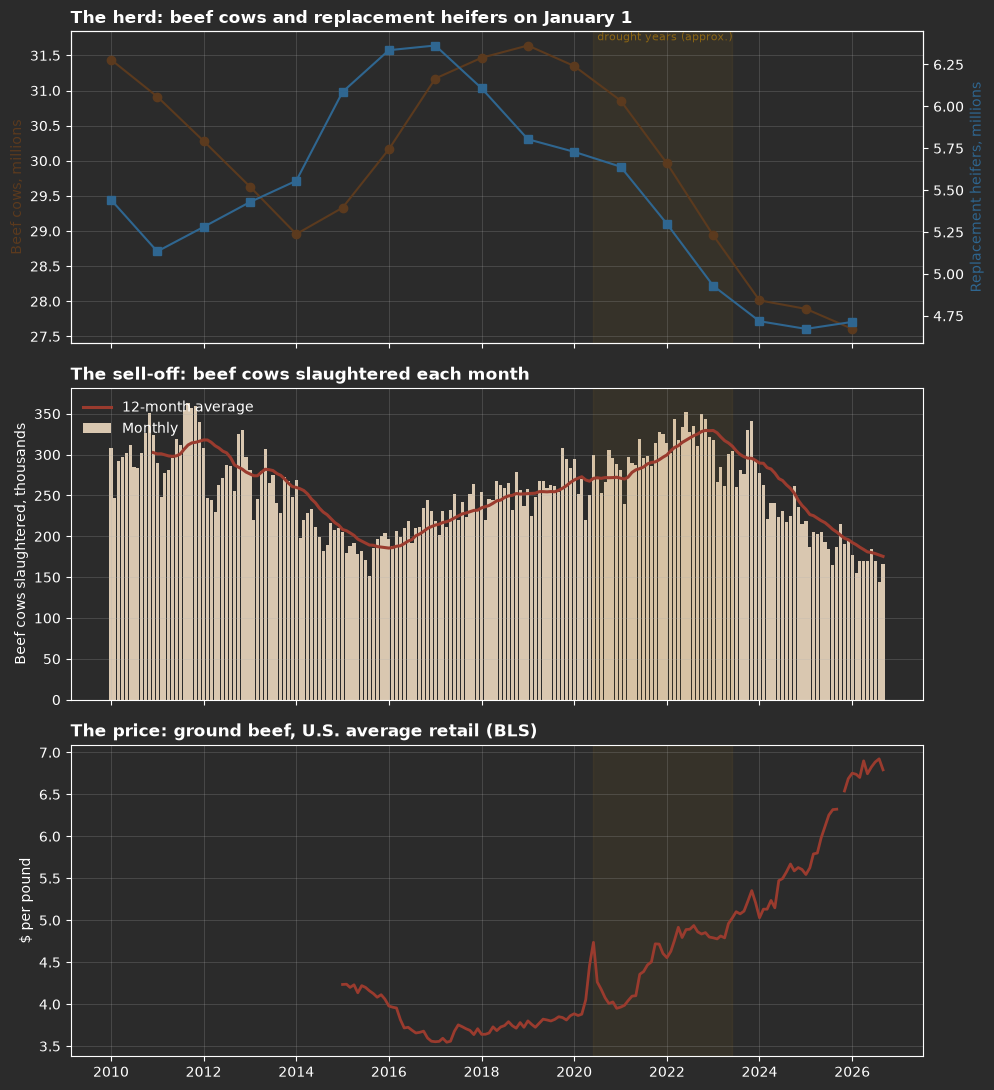

In [19]:
import matplotlib.pyplot as plt

# Ground beef price from notebook 01's most recent raw BLS file
bls_file = sorted((PROJECT_ROOT / "data" / "raw").glob("bls_prices_*.json"))[-1]
bls = json.loads(bls_file.read_text())
beef_rows = next(s for s in bls["Results"]["series"] if s["seriesID"] == "APU0000703112")["data"]
beef_price = pd.Series(
    {pd.Timestamp(int(o["year"]), int(o["period"][1:]), 1): pd.to_numeric(o["value"], errors="coerce")
     for o in beef_rows if o["period"].startswith("M") and o["period"] != "M13"}
).sort_index()

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

ax = axes[0]
jan1 = pd.to_datetime(herd.index.astype(str) + "-01-01")
ax.plot(jan1, herd["beef_cows"] / 1e6, marker="o", color="#5B3A1E", label="Beef cows")
ax.set_ylabel("Beef cows, millions", color="#5B3A1E")
ax2 = ax.twinx()
ax2.plot(jan1, herd["beef_replacement_heifers"] / 1e6, marker="s", color="#2F6690", label="Replacement heifers")
ax2.set_ylabel("Replacement heifers, millions", color="#2F6690")
ax.set_title("The herd: beef cows and replacement heifers on January 1", loc="left", fontweight="bold")
ax.grid(alpha=0.3)

ax = axes[1]
ax.bar(slaughter.index, slaughter["beef_cows_slaughtered"] / 1e3, width=25, color="#D9C7B0", label="Monthly")
ax.plot(slaughter.index, slaughter["beef_cows_slaughtered_12mo"] / 12 / 1e3, color="#9A3B2E", linewidth=2.2,
        label="12-month average")
ax.set_ylabel("Beef cows slaughtered, thousands")
ax.set_title("The sell-off: beef cows slaughtered each month", loc="left", fontweight="bold")
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(beef_price.index, beef_price, color="#9A3B2E", linewidth=2)
ax.set_ylabel("$ per pound")
ax.set_title("The price: ground beef, U.S. average retail (BLS)", loc="left", fontweight="bold")
ax.grid(alpha=0.3)

for ax in axes:
    ax.axvspan(pd.Timestamp("2020-06-01"), pd.Timestamp("2023-06-01"), color="#C08A1E", alpha=0.08)
axes[0].text(pd.Timestamp("2020-07-01"), axes[0].get_ylim()[1], "drought years (approx.)",
             va="top", fontsize=8, color="#8A6414")

fig.tight_layout()
plt.show()

### How to read it
- **Top:** the beef cow herd (brown, left axis) and replacement heifers (blue, right axis)
  each January 1.
- **Middle:** beef cows slaughtered each month (light bars) and the 12-month average
  (red line), which smooths out the fall culling season.
- **Bottom:** the ground beef price from notebook 01.
- The shaded band marks roughly mid-2020 to mid-2023, the drought years. It's a
  placeholder: item 1.6 will replace it with real drought data.

### What it means
The order matches the D17 chain:
1. **Cow slaughter rose from 2019 and peaked in 2022**, during the drought years.
2. **The herd fell** from 2019 to 2026, fastest in 2022–2024, right after the
   peak sell-off.
3. **Ground beef prices climbed** steadily from 2021, and fastest from 2024, as the
   herd reached its lowest point.
4. **Replacement heifers stayed low**, so there's no rebuild yet to bring prices down.

**One honest caveat:** cow slaughter was already rising from about 2016, and replacement
heifers started falling in 2018, *before* the drought. That's the normal cattle cycle
turning after a rebuild. The drought didn't start the decline; it **accelerated** it,
pushing cow slaughter to its 2022 peak and keeping heifers from being held back.

The 2020 price spike (COVID plant shutdowns) shows up in the bottom panel without any
change in the herd: a separate, short-lived cause. The long climb from 2021 lines up
with the herd. This is timing, not proof of cause; Milestone 4 measures the delays
between each step.

## Step 12 · Save the tables

Two processed files for the app and for Milestone 4. Like the ERS table, these are
committed to git (D9, D12).

In [20]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

herd_out = herd.reset_index()
herd_out.insert(1, "reference_date", herd_out["year"].astype(str) + "-01-01")
herd_path = PROCESSED_DIR / "nass_herd_jan1.csv"
herd_out.to_csv(herd_path, index=False)

slaughter_path = PROCESSED_DIR / "nass_slaughter_monthly.csv"
slaughter.rename_axis("date").reset_index().to_csv(slaughter_path, index=False)

for p in (herd_path, slaughter_path):
    print("Saved:", p.relative_to(PROJECT_ROOT))

Saved: data\processed\nass_herd_jan1.csv
Saved: data\processed\nass_slaughter_monthly.csv


## What's next and why

**Item 1.6: drought data** (`04_drought.ipynb`). This notebook shows the sell-off and the
shrinking herd lined up with the drought years, but the shaded band in the chart is only
an approximation. The U.S. Drought Monitor gives the real timing: how much of the main
cattle states was in drought, month by month. That's the first link in the D17 chain,
and the one we haven't measured yet.